# Mushrooms (Classification)
## CS 1783 Artificial Intelligence Programming
### Jacob Shultz

In [274]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import validation
from torch.utils.data import TensorDataset, DataLoader, random_split

## 1. Load and clean data

In [275]:
path = 'datasets/agaricus-lepiota.data'
lbls = ['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
        'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring',
        'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

df = pd.read_csv(path, header=None, names=lbls, na_values='?')
print(df.shape)
df.head()

(8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [276]:
for col in df:
    print(f"{col}:\n{df[col].unique()}\n\n")

class:
<StringArray>
['p', 'e']
Length: 2, dtype: str


cap-shape:
<StringArray>
['x', 'b', 's', 'f', 'k', 'c']
Length: 6, dtype: str


cap-surface:
<StringArray>
['s', 'y', 'f', 'g']
Length: 4, dtype: str


cap-color:
<StringArray>
['n', 'y', 'w', 'g', 'e', 'p', 'b', 'u', 'c', 'r']
Length: 10, dtype: str


bruises:
<StringArray>
['t', 'f']
Length: 2, dtype: str


odor:
<StringArray>
['p', 'a', 'l', 'n', 'f', 'c', 'y', 's', 'm']
Length: 9, dtype: str


gill-attachment:
<StringArray>
['f', 'a']
Length: 2, dtype: str


gill-spacing:
<StringArray>
['c', 'w']
Length: 2, dtype: str


gill-size:
<StringArray>
['n', 'b']
Length: 2, dtype: str


gill-color:
<StringArray>
['k', 'n', 'g', 'p', 'w', 'h', 'u', 'e', 'b', 'r', 'y', 'o']
Length: 12, dtype: str


stalk-shape:
<StringArray>
['e', 't']
Length: 2, dtype: str


stalk-root:
<StringArray>
['e', 'c', 'b', 'r', nan]
Length: 5, dtype: str


stalk-surface-above-ring:
<StringArray>
['s', 'f', 'k', 'y']
Length: 4, dtype: str


stalk-surface-below

In [277]:
# convert into one-hot encoding

df = pd.get_dummies(df)
print(df.shape)
df.head()

(8124, 118)


,class_e,class_p,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,False,True,False,False,False,False,False,True,False,False,...,True,False,False,False,False,False,False,False,True,False
1,True,False,False,False,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,False
2,True,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
3,False,True,False,False,False,False,False,True,False,False,...,True,False,False,False,False,False,False,False,True,False
4,True,False,False,False,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,False


In [278]:
# train-test-split
X = df.iloc[:, 2:]
y = df.iloc[:, :2]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)
y_train.head()

(6499, 116) (6499, 2)
(1625, 116) (1625, 2)


,class_e,class_p
4984,True,False
5585,False,True
3323,False,True
3047,False,True
1512,True,False


In [279]:
# convert Pandas DataFrames to Pytorch tensors
X_train_tsor = torch.tensor(X_train.to_numpy(dtype=np.float32), dtype=torch.float32)
y_train_tsor = torch.tensor(y_train.to_numpy(dtype=np.float32), dtype=torch.float32)

X_test_tsor = torch.tensor(X_test.to_numpy(dtype=np.float32), dtype=torch.float32)
y_test_tsor = torch.tensor(y_test.to_numpy(dtype=np.float32), dtype=torch.float32)

print(X_train_tsor.shape, y_train_tsor.shape)
print(X_test_tsor.shape, y_test_tsor.shape)

torch.Size([6499, 116]) torch.Size([6499, 2])
torch.Size([1625, 116]) torch.Size([1625, 2])


## 2. Build Neural Network

In [280]:
# batches
train_tsor_dataset = TensorDataset(X_train_tsor, y_train_tsor)

train_batches = DataLoader(
    train_tsor_dataset,
    batch_size=64,
    shuffle=True
)

In [281]:
model = torch.nn.Sequential(
        # input
        torch.nn.Linear(116, 50),
        torch.nn.ReLU(),
        torch.nn.Dropout(0.0),

        # Output
        torch.nn.Linear(50, 2),
)

In [282]:
# model = torch.nn.Sequential(
#         # input
#         torch.nn.Linear(116, 1000),
#         torch.nn.ReLU(),
#         torch.nn.Dropout(0.7),

#         # Hidden
#         torch.nn.Linear(1000, 1000),
#         torch.nn.ReLU(),
#         torch.nn.Dropout(0.7),

#         # Output
#         torch.nn.Linear(1000, 2),
# )

In [283]:
loss_function = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [284]:
# training
epochs = 5
train_losses = []
log: str = "Training:\n"

for epoch in range(epochs):
    avg_loss = 0
    epoch_losses = []

    for inputs, outputs in train_batches:
        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        preds = model(inputs)

        # Calculate Loss and accuracy
        loss = loss_function(preds, outputs)

        # Gradients
        loss.backward()
        epoch_losses.append(loss.item())

        # Update weights
        optimizer.step()


    avg_loss = sum(epoch_losses) / len(epoch_losses)
    if (epoch + 1) % (epochs // 5) == 0:
        print(
            f"Epoch {epoch + 1}/{epochs}\t"
            f"Loss: {avg_loss:.6f}"
        )
        
    log += f"Epoch {epoch + 1}/{epochs}\tLoss: {avg_loss:.6f}\n"

    train_losses.append(avg_loss)

Epoch 1/5	Loss: 0.284786
Epoch 2/5	Loss: 0.041219
Epoch 3/5	Loss: 0.015950
Epoch 4/5	Loss: 0.008272
Epoch 5/5	Loss: 0.005035


In [285]:
# validation

model.eval()
correct = 0

with torch.no_grad():

  preds = model(X_test_tsor)
  loss = loss_function(preds, y_test_tsor)
  pred_classes = torch.argmax(preds, dim=1)
  actual_classes = torch.argmax(y_test_tsor, dim=1)
  accuracy = (pred_classes == actual_classes).sum().item() / len(actual_classes)

  print(f"Test Loss: {loss.item():.6f}\tAccuracy: {accuracy:.6f}")
  log += f"\nValidation\n"
  log += f"Test Loss: {loss.item():.6f}\tAccuracy: {accuracy:.6f}\n"


Test Loss: 0.003578	Accuracy: 1.000000


## 3. Output metrics

/tmp/ipykernel_129113/1311780973.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


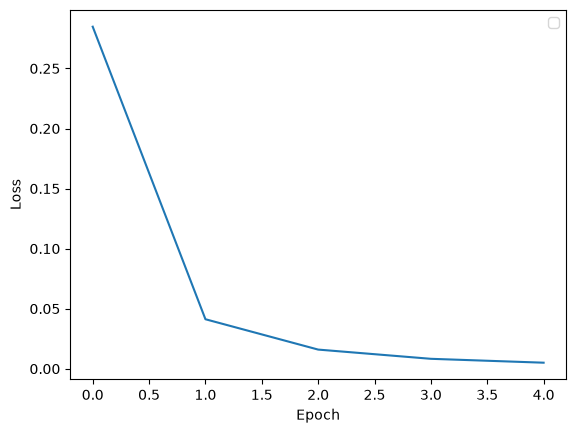

In [286]:
# plot metrics

plt.plot(train_losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [287]:
with open("log.txt", "w") as f:
    f.write(log)